# Natural-Language Experiments - Summary

**Question:** Do the synthetic *disambiguation-complexity* findings transfer to natural text, where many
overlapping cues are present at once? 

The following experiments test this by manipulating the explicit conditioning
structure of WikiText sequences and measuring how fast a small GPT-2 memorizes them.

**Summary of Findings:** every condition is memorized fully (exact-match of 1.0), and the manipulations move
memorization *speed* only marginally — often in the direction *opposite* to the hypothesis. The
natural-language results are therefore **neutral**: consistent with the framework but not confirmatory,
because implicit linguistic redundancy is enough to disambiguate on its own.

In [1]:
# Load data from wandb (plotting code is in a separate file `nl_plots.py`)

import nl_plots as nlp

runs = nlp.load_runs()
hist = nlp.load_histories(runs)

print(f'{len(runs)} NL runs, {len(hist)} with usable history')

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /Users/rorro/.netrc.
wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /Users/rorro/.netrc.
wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /Users/rorro/.netrc.
wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /Users/rorro/.netrc.


histories ready: 39 / 45  (cache: /Users/rorro/Projects/memorization-llms/analysis/.wandb_cache)
45 NL runs, 39 with usable history


## Shared setup

- Dataset sizes are between 1-2 thousand sequences.
- Each WikiText sequence in the datasets has 100 tokens (50-token prefix + 50-token suffix).
- We use the **AdamW** optimizer with a learning rate of **5e-4**, batch size of **64**, **bf16** precision, and a cosine schedule with 100 steps warmup for 2000 optimization steps.

---
## 1. Prefix structure — fixed-position cues

**Aim.** Start from the original WikiText prefix, then (a) *translate* the
prefix and (b) insert a **unique identifier** token at a fixed position (pos 0 or pos 5) that could in
principle serve as a single-token key to the suffix. If memorization in natural language were driven by
one explicit cue (a Level-1-style condition), the UID variants should be memorized faster.

`o200k_base` is a multilingual tokenizer introduced for the natural language experiments, it has about x4 times the amount of tokens than GPT-2 tokenizer.


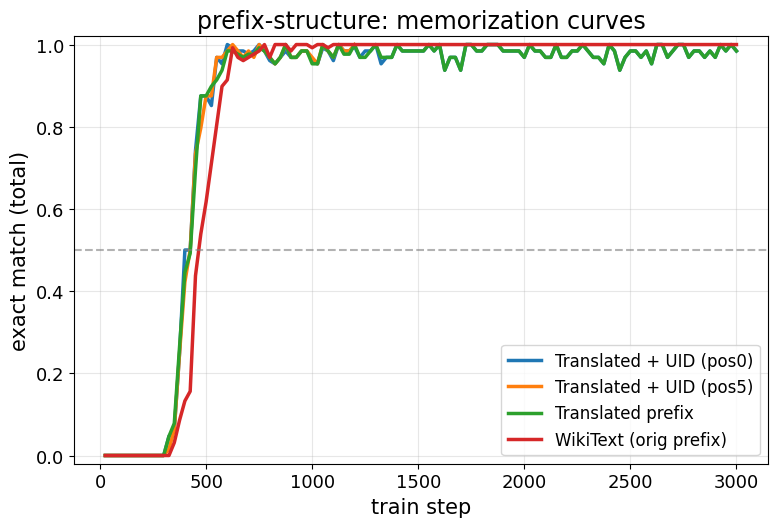

In [2]:
nlp.plot_family(runs, hist, 'prefix-structure')

**Interpretation.** The original natural-language prefix is slowest, translating + inserting a fixed unique-ID speeds
up memorization slightly. The direction is *consistent* with the disambiguation framework (a cleaner explicit
cue should lead to faster memorization), but the effect is almost insignificant. 

In the attention analaysis (shown in final report), the model spreads attention across many prefix positions instead of locking onto the inserted cue. The hypothesis is that natural language has high, heterogeneous effective arity, so a single embedded cue is comparatively unimportant.

---
## 2. Translation

**Aim.** Translate whole sequences into a **Latin-family** group (Spanish, Portuguese, French, Italian)
vs a **diverse-family** group (Russian, Chinese, Tamil, Arabic), tokenized with the multilingual
`o200k_base`. This varies the amount of collisions in the prefix: the latin group is expected
to have more collisions than the diverse group.

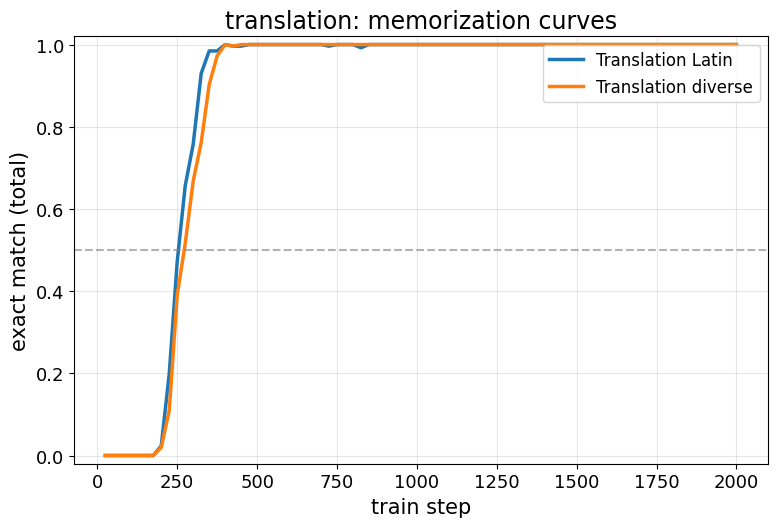

In [3]:
nlp.plot_family(runs, hist, 'translation')

**Interpretation.** Latin and diverse curves are essentially identical, both
reaching full memorization. The language family of the prefix does not meaningfully change memorization
speed — the model memorizes Tamil/Arabic sequences about as fast as Spanish/French.

---
## 3. Multilingual — shared English suffix 

**Aim.** Translate the **prefix only** per language but
pair every variant with a **common English suffix** computed jointly across groups. This isolates whether
reducing familiarity of the conditioning context (the prefix) alters how quickly a shared target is
memorized, again split into Latin vs diverse language groups.

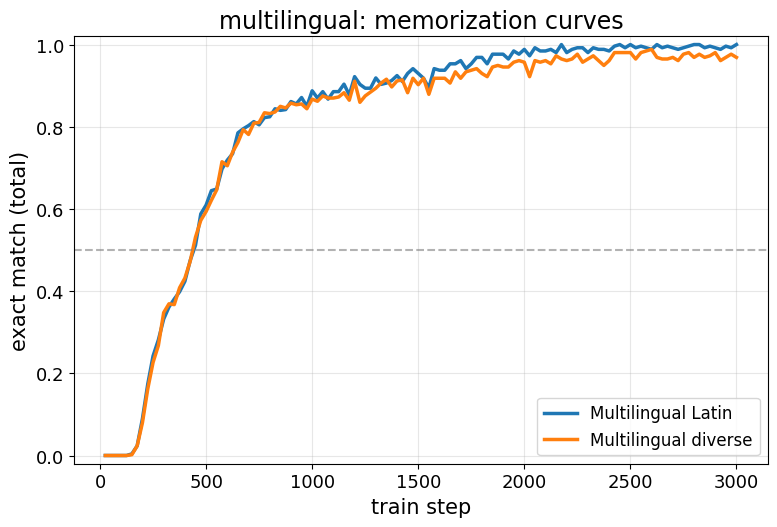

In [4]:
nlp.plot_family(runs, hist, 'multilingual')

**Interpretation.** Latin vs diverse are again near-identical.. Even with a
shared English suffix and a foreign-language prefix, reducing the model's prior exposure does not change
memorization dynamics — the result reinforces the translation finding.

---
## 4. Paraphrase

**Aim.** Take US-politics sequences, generate ~9 semantically
equivalent paraphrases each, and compare against a control of independent WikiText sequences. If shared
semantic content across paraphrases makes their suffixes **harder to disambiguate** from one another, the
paraphrase group should memorize *more slowly* than the control.

In this experiment we use the `gpt-2` tokenizer. 

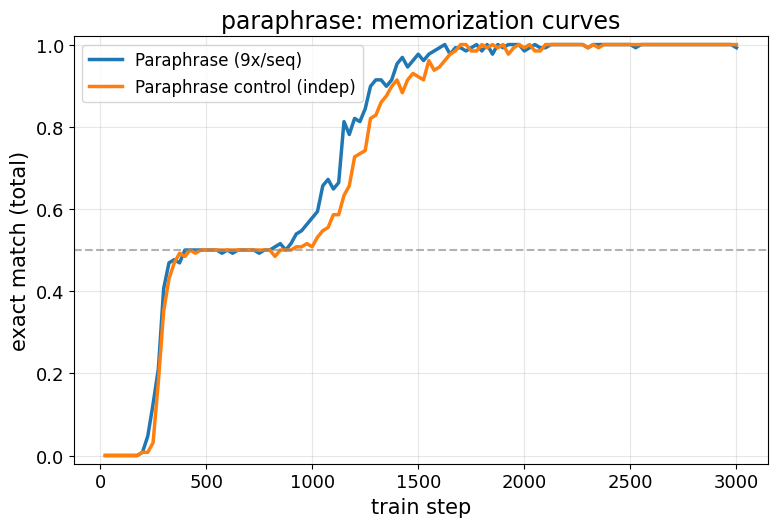

In [5]:
nlp.plot_family(runs, hist, 'paraphrase')

**Interpretation.** The result is **null and in the wrong direction**: the paraphrase set is if anything
marginally *faster* than the independent control, not slower. Shared semantics
across paraphrases did not create the predicted disambiguation bottleneck.

---
## 5. Prefix-paraphrase

**Aim.** Isolate prefix-side conditioning structure: paraphrase **only the prefix** while holding the
suffix fixed (~100 source sequences × 10 versions ≈ 1000 rows), vs a matched control. This tests whether
varying just the conditioning context — with the target held constant — changes memorization speed.


In this experiment we use the `gpt-2` tokenizer. 

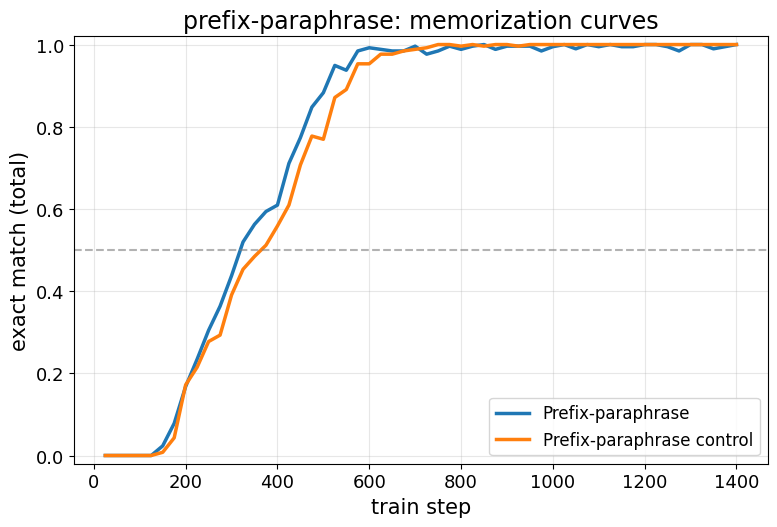

In [6]:
nlp.plot_family(runs, hist, 'prefix-paraphrase')

**Interpretation.** Paraphrasing the prefix while fixing the suffix leaves memorization speed essentially
unchanged. Varying the conditioning context alone does not isolate a conditioning-
complexity effect.